# Visualizing the training data and augmentations

This notebook shows exactly what the encoder will receive during multi-crop
WS-DINO training:

1. **Dataset facts**: frame interval, frame_gap, t1 window, z window, crop sizes.
2. **Raw biology**: full field-of-view mean projections across the t1 window.
3. **One sample**: the 2 globals (one at t1, one at t2) and the locals.
4. **Multi-crop layout**: the global window + locals overlaid on the t1 frame,
   colored by parent so you can eyeball nesting.
5. **Intensity gate**: distribution of random crop means vs the gate threshold,
   plus example accepted/rejected crops — for sanity-checking the gate.
6. **Depth montage**: the z slab inside the t1 global.
7. **Augmentation grid**: 16 independent augmentations of the same crop.
8. **Per-augmentation isolation**: effect of each augmentation on its own.
9. **One real batch**: what the DataLoader actually hands to the model.

Each cell is independent. Re-run cells after editing `cfg` to see the effect.

In [1]:
# setup: build cfg, pick zarr (or use multi-zarr from yaml), build dataset, define helpers.
import sys, os, time, copy
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from configs.config import Config
from data.dataset import ZarrCellDataset, MultiZarrDataset, worker_init_fn
from data.picker import pick_zarr_path
from data.augmentations import build_augmentations

# load defaults; swap for `Config.from_yaml('../configs/train.yaml')` to use the yaml.
cfg = Config.from_yaml("../configs/train.yaml")
# fresh seed per notebook run so each session sees different crops.
cfg.seed = time.time_ns() % (2**31 - 1)

# anchor any relative paths in the yaml to the project root so the notebook
# works regardless of where jupyter was launched from.
_project_root = os.path.abspath('..')
if not os.path.isabs(cfg.training_data_index_path):
    cfg.training_data_index_path = os.path.join(_project_root, cfg.training_data_index_path)

# build the right dataset shape.
if cfg.zarr_paths:
    ds = MultiZarrDataset(cfg)
    primary = ds.children[0]  # used for single-crop visualizations below
    is_multi = True
else:
    if cfg.zarr_path is None:
        cfg.zarr_path = pick_zarr_path()
    ds = ZarrCellDataset(cfg)
    primary = ds
    is_multi = False

sample_iter = iter(ds)

print('is_multi             :', is_multi)
print('seed                 :', cfg.seed)
print('n_local_crops        :', cfg.n_local_crops, '(split evenly between the 2 globals)')
print('global_crop_size     :', cfg.global_crop_size)
print('local_crop_size      :', cfg.local_crop_size)
print('z_thickness (global) :', cfg.z_thickness)
print('local_z_thickness    :', cfg.local_z_thickness)
print('intensity_min_frac   :', cfg.intensity_min_frac)
print('target_gap_minutes   :', cfg.target_gap_minutes)
print('temporal_direction   :', cfg.temporal_direction)
print()
if is_multi:
    print(f'mixed across {len(ds.children)} datasets:')
    for i, c in enumerate(ds.children):
        print(f'  [{i}] {c.cfg.zarr_path}')
        print(f'      shape={tuple(c.arr.shape)} interval_min={c.interval_minutes} frame_gap={c.frame_gap}')
else:
    print('zarr_path            :', primary.cfg.zarr_path)
    print('arr.shape (T,C,Z,Y,X):', tuple(primary.arr.shape))
    print('interval_minutes     :', primary.interval_minutes)
    print('frame_gap (frames)   :', primary.frame_gap)
    print(f'wall-clock gap       : {primary.frame_gap * primary.interval_minutes:.1f} min')
    print('t1 window            :', (primary.t1_min, primary.t1_max))
    print('z window             :', (primary.z_min, primary.z_max))


# ----- visualization helpers -----

def mean_projection(volume):
    """average across z; gives a clean 2d view of a (z, h, w) volume."""
    return volume.mean(axis=0)


def mip(volume):
    """max projection across z; bright structures stand out."""
    return volume.max(axis=0)


def z_montage(volume, ncols=5):
    """tile z slices side by side into one image."""
    z, h, w = volume.shape
    nrows = (z + ncols - 1) // ncols
    out = np.zeros((nrows * h, ncols * w), dtype=volume.dtype)
    for i in range(z):
        r, c = divmod(i, ncols)
        out[r*h:(r+1)*h, c*w:(c+1)*w] = volume[i]
    return out


def percentile_limits(values, low=1.0, high=99.0):
    """display limits robust to a few bright outliers."""
    lo, hi = np.percentile(np.asarray(values), [low, high])
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        lo, hi = float(np.min(values)), float(np.max(values))
    if hi <= lo:
        hi = lo + 1e-6
    return float(lo), float(hi)


def show_gray(ax, image, title, limits):
    ax.imshow(image, cmap='gray', vmin=limits[0], vmax=limits[1])
    ax.set_title(title, fontsize=10)
    ax.axis('off')


def raw_frame_mean(child, t, z0, z1):
    """full-frame mean projection in normalized [0, 1] intensity (pre-augmentation)."""
    vol = child.arr[int(t), child.cfg.channel, int(z0):int(z1), :, :].compute()
    vol = np.asarray(vol, dtype=np.float32)
    return (np.clip(vol, 0, child.cfg.max_intensity) / child.cfg.max_intensity).mean(axis=0)


def load_crop_tensor(child, t, z, y, x, size, z_thickness=None):
    """raw->normalized [1, z, h, w] tensor matching what _sample_pair produces pre-augment."""
    raw = child._load_crop_raw(int(t), int(z), int(y), int(x), int(size), int(size),
                               z_thickness=z_thickness)
    return child._to_tensor(raw)

[ZarrCellDataset] opened /Volumes/sgrolab/jennifer/cryolite/cryolite_mixin_test65_2024-04-16/NC28.1_overnight_day1/2024-04-16_ERH_mixin65_plate1_NC28.1_overnight_ERH Red FarRed.zarr shape=(145, 2, 179, 1907, 1443) chunks=((1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1), (1, 1), (1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

## 1. Raw biology: the field of view over time

Full-frame mean projections at evenly-spaced timepoints, in normalized `[0, 1]` intensity (clip → divide by `max_intensity`). No augmentations, no cropping — this is what's *inside* the zarr.

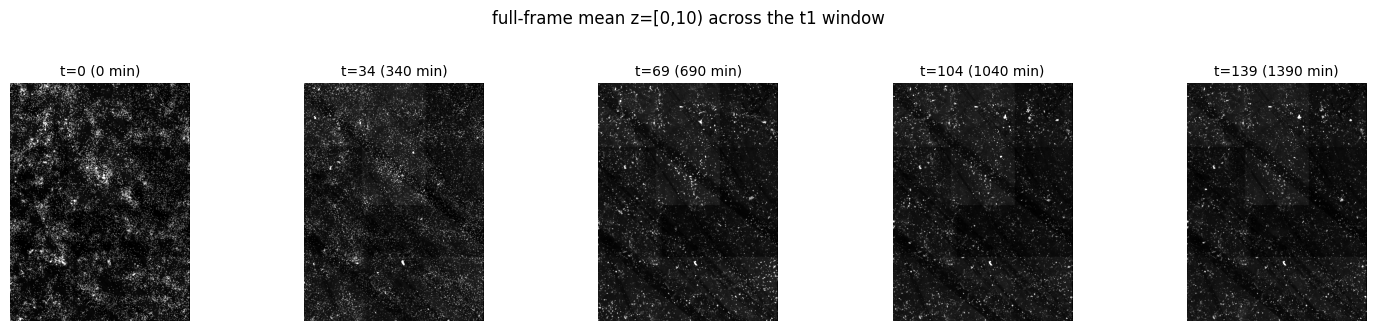

In [2]:
n_panels = 5
ts = np.linspace(primary.t1_min, primary.t1_max - 1, n_panels).astype(int)
z0 = primary.z_min
z1 = z0 + cfg.z_thickness

frames = [raw_frame_mean(primary, t, z0, z1) for t in ts]
lims = percentile_limits(np.concatenate([f.ravel() for f in frames]), 0.5, 99.5)

fig, axes = plt.subplots(1, n_panels, figsize=(3 * n_panels, 3.2))
for ax, f, t in zip(axes, frames, ts):
    mins = t * primary.interval_minutes
    show_gray(ax, f, f't={int(t)} ({mins:.0f} min)', lims)
plt.suptitle(f'full-frame mean z=[{z0},{z1}) across the t1 window', y=1.02)
plt.tight_layout(); plt.show()


## 2. One sample: 2 globals + locals

Each sample from the dataset is a multi-crop bundle:

- `globals`: a `(2, 1, z_thickness, h, w)` tensor. Index 0 is the t1 view, index 1 is the t2 view. Both share the same `(y, x)` offset and z slab; only the timepoint differs.
- `locals`: a `(n_local_crops, 1, local_z_thickness, h_local, w_local)` tensor. Each local picks its own time in `[t1, t2]`, a contiguous `local_z_thickness` sub-slab inside the global z window, and an `(y, x)` nested in its parent global's spatial window. Locals are split evenly between the two globals as spatial parents (recorded in `meta['local_parent']`).
- `weak_label`: a `(dataset_idx, frame_gap)` long tensor.

All tensors are post-augmentation. Loss-wise, both globals go through student + teacher; locals go through student only, and each local is pulled toward both teacher globals.

sample keys          : ['globals', 'weak_label', 'meta', 'locals']
globals shape        : (2, 1, 10, 256, 256)
locals shape         : (6, 1, 5, 96, 96)
weak_label           : [1, 10] (dataset_idx, frame_gap)
t1 / t2              : 77 / 87
frame_gap            : 10
global z slab        : (59, 69)
global (y, x)        : (152, 1017)
local parents        : [0, 0, 0, 1, 1, 1]
local times          : [77, 86, 87, 78, 80, 82]
local z starts       : [62, 60, 64, 62, 64, 61]
local offsets (y, x) : [(296, 1031), (309, 1026), (174, 1085), (283, 1053), (281, 1032), (278, 1081)]


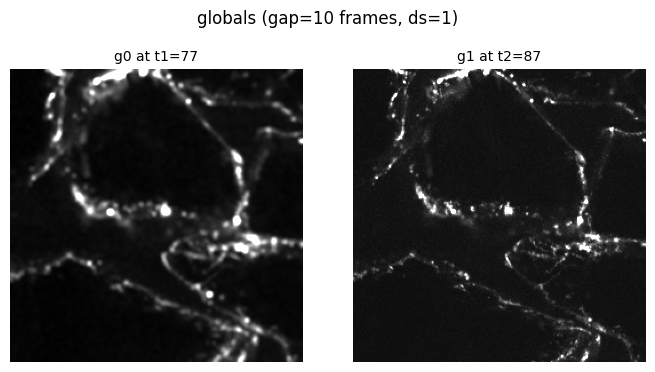

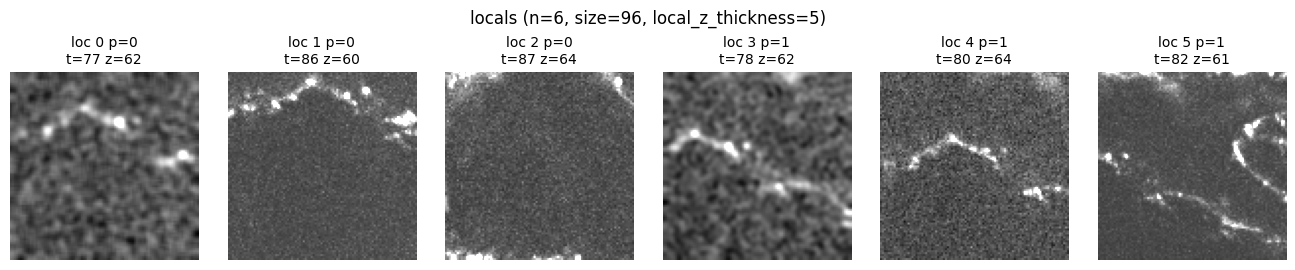

In [3]:
sample = next(sample_iter)
meta = sample['meta']
weak_label = sample['weak_label']

# resolve the child this sample came from so per-frame helpers work in the multi-zarr case.
src = ds.children[int(meta['dataset_idx'])] if is_multi else primary

globs = sample['globals'].numpy()  # (2, 1, z, h, w)
has_locals = 'locals' in sample
loc = sample['locals'].numpy() if has_locals else None

print('sample keys          :', list(sample.keys()))
print('globals shape        :', globs.shape)
if has_locals:
    print('locals shape         :', loc.shape)
print('weak_label           :', weak_label.tolist(), '(dataset_idx, frame_gap)')
print('t1 / t2              :', int(meta['t1']), '/', int(meta['t2']))
print('frame_gap            :', int(meta['frame_gap']))
print('global z slab        :', (int(meta['z']), int(meta['z_end'])))
print('global (y, x)        :', (int(meta['global_y']), int(meta['global_x'])))
if has_locals:
    print('local parents        :', meta['local_parent'].tolist())
    print('local times          :', meta['local_t'].tolist())
    print('local z starts       :', meta['local_z'].tolist())
    print('local offsets (y, x) :', list(zip(meta['local_y'].tolist(), meta['local_x'].tolist())))

# globals: one row, two columns (g0 at t1, g1 at t2).
pool = globs.ravel()
glims = percentile_limits(pool, 1.0, 99.0)
fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
show_gray(axes[0], mean_projection(globs[0, 0]), f'g0 at t1={int(meta["t1"])}', glims)
show_gray(axes[1], mean_projection(globs[1, 0]), f'g1 at t2={int(meta["t2"])}', glims)
plt.suptitle(f'globals (gap={int(meta["frame_gap"])} frames, ds={int(meta["dataset_idx"])})', y=1.02)
plt.tight_layout(); plt.show()

# locals: tile, titled with parent index, time, and z start.
if has_locals:
    n_l = loc.shape[0]
    llims = percentile_limits(loc, 1.0, 99.0)
    ncols = min(n_l, 6)
    nrows = (n_l + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.2 * ncols, 2.6 * nrows), squeeze=False)
    parents = meta['local_parent'].tolist()
    times = meta['local_t'].tolist()
    zs = meta['local_z'].tolist()
    for i in range(nrows * ncols):
        ax = axes[i // ncols, i % ncols]
        if i < n_l:
            title = f'loc {i} p={parents[i]}\nt={times[i]} z={zs[i]}'
            show_gray(ax, mean_projection(loc[i, 0]), title, llims)
        else:
            ax.axis('off')
    plt.suptitle(f'locals (n={n_l}, size={cfg.local_crop_size}, local_z_thickness={cfg.local_z_thickness})', y=1.02)
    plt.tight_layout(); plt.show()
else:
    print('n_local_crops=0; skipping locals panel.')

## 3. Multi-crop layout: are the locals actually nested?

The global window is outlined in yellow on the full t1 frame. Each local is drawn dashed, colored by its parent global (`parent=0` → cyan, `parent=1` → magenta). Since both globals share the same `(y, x)`, there's only one global rectangle on screen; locals from both parents land inside it. If the geometry is right, every dashed rectangle sits fully inside the yellow one.

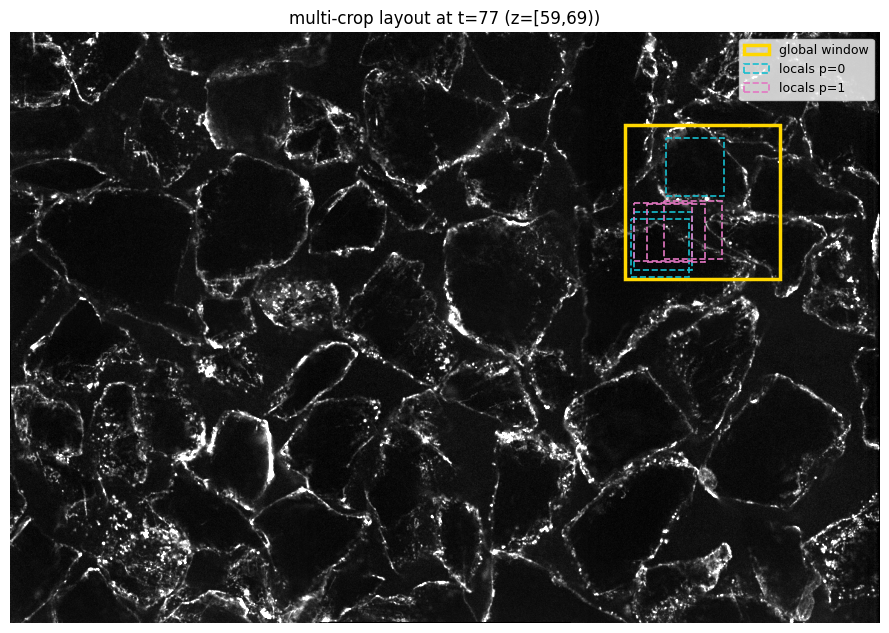

In [4]:
frame = raw_frame_mean(src, int(meta['t1']), int(meta['z']), int(meta['z_end']))
flims = percentile_limits(frame, 0.5, 99.0)

g_size = cfg.global_crop_size
l_size = cfg.local_crop_size
gy = int(meta['global_y'])
gx = int(meta['global_x'])

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(frame, cmap='gray', vmin=flims[0], vmax=flims[1])

ax.add_patch(patches.Rectangle((gx, gy), g_size, g_size,
                               linewidth=2.5, edgecolor='gold', facecolor='none',
                               label='global window'))

if has_locals:
    parents = meta['local_parent'].tolist()
    lys = meta['local_y'].tolist()
    lxs = meta['local_x'].tolist()
    parent_colors = {0: 'tab:cyan', 1: 'tab:pink'}
    seen = set()
    for j in range(len(parents)):
        p = parents[j]
        label = f'locals p={p}' if p not in seen else None
        seen.add(p)
        ax.add_patch(patches.Rectangle((lxs[j], lys[j]), l_size, l_size,
                                       linewidth=1.2, edgecolor=parent_colors.get(p, 'white'),
                                       facecolor='none', linestyle='--', label=label))

ax.legend(loc='upper right', fontsize=9)
ax.set_title(f'multi-crop layout at t={int(meta["t1"])} (z=[{int(meta["z"])},{int(meta["z_end"])}))')
ax.axis('off')
plt.tight_layout(); plt.show()

## 4. Intensity gate: are we actually rejecting background?

`_sample_pair` accepts a global crop only when its raw mean over the z slab is
at least `intensity_min_frac * slab_mean(t1, z)`. The slab mean is the average
intensity over the same `[z, z+z_thickness)` slab the crop is drawn from
(not the full configured z window), so the threshold and the crop means live
in identical units and the comparison is meaningful. Two sanity checks:

- Histogram of crop means at many random `(y, x)` offsets, with the threshold
  drawn in. The gate should bisect background-only crops on the left from
  cell-containing crops on the right.
- A few example crops below and above the threshold.

If the histogram looks unimodal at the gate, the threshold is too aggressive
(or too permissive) for this dataset and `intensity_min_frac` needs a tweak.

slab_mean (raw)      : 601.29  (z=[59, 69))
threshold (raw)      : 571.23  (intensity_min_frac=0.95)
random crop accept % : 87.2% of 400 probes


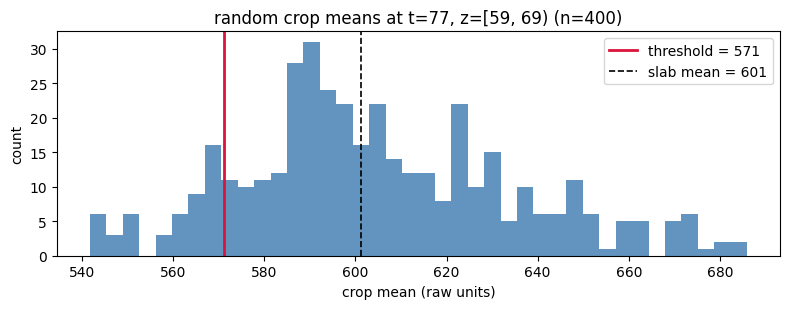

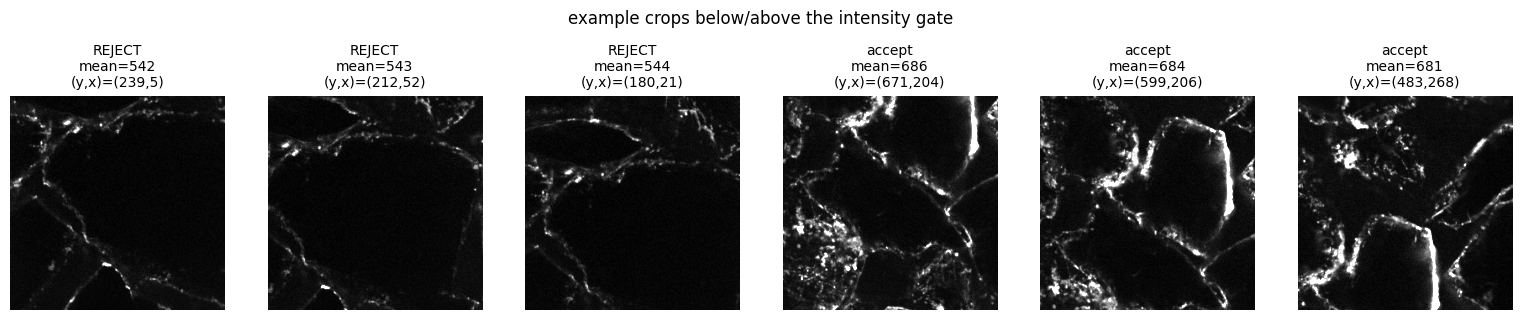

In [5]:
n_probe = 400
rng_probe = np.random.default_rng(cfg.seed + 1)
t_probe = int(meta['t1'])
z_probe = int(meta['z'])

# slab mean over [z, z+z_thickness) in raw units. mirrors
# ZarrCellDataset._get_frame_mean so the threshold here equals the one
# _sample_pair actually uses.
def raw_slab_mean(child, t, z):
    sub = child.arr[int(t), child.cfg.channel,
                    int(z):int(z) + child.cfg.z_thickness, :, :].compute()
    return float(np.asarray(sub, dtype=np.float32).mean())

slab_mean_raw = raw_slab_mean(src, t_probe, z_probe)
threshold_raw = cfg.intensity_min_frac * slab_mean_raw
print(f'slab_mean (raw)      : {slab_mean_raw:.2f}  (z=[{z_probe}, {z_probe + cfg.z_thickness}))')
print(f'threshold (raw)      : {threshold_raw:.2f}  (intensity_min_frac={cfg.intensity_min_frac})')

# sample random crop means at random (y, x) offsets.
crop_means = []
crop_samples = []  # keep raw arrays for the example panel below
for _ in range(n_probe):
    y = int(rng_probe.integers(0, src.Y - g_size + 1))
    x = int(rng_probe.integers(0, src.X - g_size + 1))
    raw = src._load_crop_raw(t_probe, z_probe, y, x, g_size, g_size)
    crop_means.append(float(raw.mean()))
    crop_samples.append((y, x, raw))

crop_means = np.asarray(crop_means)
accept_frac = float((crop_means >= threshold_raw).mean())
print(f'random crop accept % : {100 * accept_frac:.1f}% of {n_probe} probes')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(crop_means, bins=40, color='steelblue', alpha=0.85)
ax.axvline(threshold_raw, color='crimson', linewidth=2, label=f'threshold = {threshold_raw:.0f}')
ax.axvline(slab_mean_raw, color='black', linestyle='--', linewidth=1.2,
           label=f'slab mean = {slab_mean_raw:.0f}')
ax.set_xlabel('crop mean (raw units)')
ax.set_ylabel('count')
ax.set_title(f'random crop means at t={t_probe}, z=[{z_probe}, {z_probe + cfg.z_thickness}) (n={n_probe})')
ax.legend()
plt.tight_layout(); plt.show()

# example crops: 3 below threshold, 3 above. mean projection in normalized [0,1] for display.
below = sorted([s for s in crop_samples if s[2].mean() <  threshold_raw], key=lambda s: s[2].mean())[:3]
above = sorted([s for s in crop_samples if s[2].mean() >= threshold_raw], key=lambda s: -s[2].mean())[:3]
examples = below + above
if examples:
    norm_imgs = [(np.clip(r, 0, cfg.max_intensity) / cfg.max_intensity).mean(axis=0) for _, _, r in examples]
    lims = percentile_limits(np.concatenate([im.ravel() for im in norm_imgs]), 1.0, 99.0)
    fig, axes = plt.subplots(1, len(examples), figsize=(2.6 * len(examples), 3.0))
    if len(examples) == 1:
        axes = [axes]
    for ax, (y, x, raw), img in zip(axes, examples, norm_imgs):
        verdict = 'REJECT' if raw.mean() < threshold_raw else 'accept'
        show_gray(ax, img, f'{verdict}\nmean={raw.mean():.0f}\n(y,x)=({y},{x})', lims)
    plt.suptitle('example crops below/above the intensity gate', y=1.05)
    plt.tight_layout(); plt.show()

## 5. Depth montage: what the z slab looks like

The encoder receives a `(1, z_thickness, H, W)` tensor per crop. This montages the z slices of one global so you can see what's stacked together.

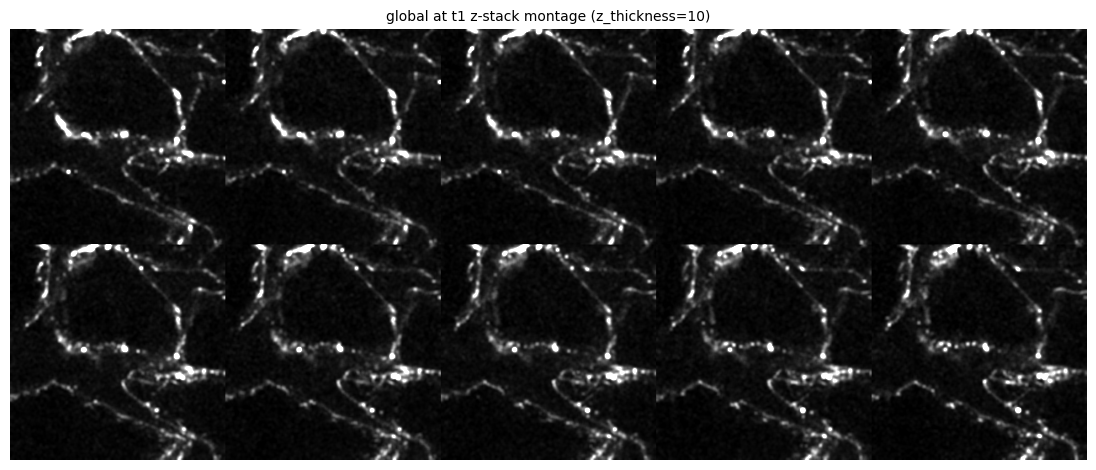

In [6]:
volume = globs[0, 0]  # global at t1
montage = z_montage(volume)
mlims = percentile_limits(volume, 1.0, 99.0)
fig, ax = plt.subplots(figsize=(12, 12 * (montage.shape[0] / montage.shape[1])))
show_gray(ax, montage, f'global at t1 z-stack montage (z_thickness={cfg.z_thickness})', mlims)
plt.tight_layout(); plt.show()

## 6. 16 independent augmentations of the same crop

Same anchor every time; only the augmentation roll changes. Use this to gauge whether augmentations are strong enough to corrupt surface noise but not so strong they destroy biology. The anchor is a freshly-loaded global crop at the current sample's `(t1, z, y, x)`.

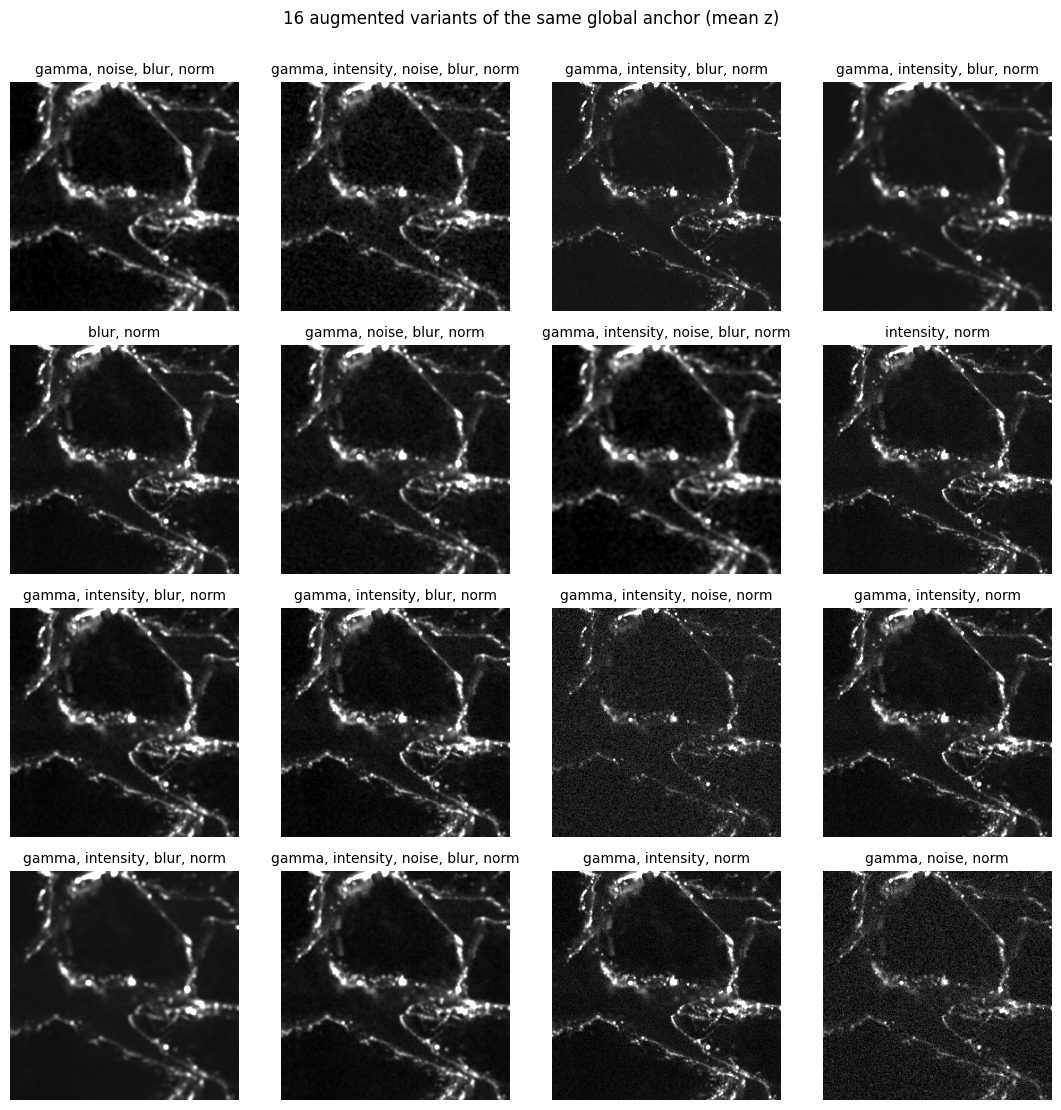

In [7]:
import torch
from data.augmentations import RandomIntensity, RandomGamma, GaussianNoise, GaussianBlur, PerCropNormalize

# short label per aug type for the panel titles.
_AUG_LABEL = {
    RandomGamma: 'gamma',
    RandomIntensity: 'intensity',
    GaussianNoise: 'noise',
    GaussianBlur: 'blur',
    PerCropNormalize: 'norm',
}


def augment_with_log(pipeline, x):
    """step through the pipeline manually so we can record which augs fired.

    mirrors `_Aug.__call__`: skip if disabled, roll `torch.rand() < p`, else apply.
    PerCropNormalize has `p=1.0` and always fires when enabled.
    """
    fired = []
    for t in pipeline.augs:
        if not t.cfg.enabled:
            continue
        if torch.rand(()).item() >= t.cfg.p:
            continue
        x = t._apply(x)
        fired.append(_AUG_LABEL.get(type(t), type(t).__name__))
    return x, fired


gy0 = int(meta['global_y'])
gx0 = int(meta['global_x'])
base = load_crop_tensor(src, int(meta['t1']), int(meta['z']),
                        gy0, gx0, cfg.global_crop_size)
augment = build_augmentations(cfg)

samples = []
labels = []
for _ in range(16):
    out, fired = augment_with_log(augment, base.clone())
    samples.append(mean_projection(out[0].numpy()))
    labels.append(', '.join(fired) if fired else 'none')
lims = percentile_limits(np.concatenate([s.ravel() for s in samples]), 1.0, 99.0)

fig, axes = plt.subplots(4, 4, figsize=(11, 11))
for ax, img, label in zip(axes.flat, samples, labels):
    show_gray(ax, img, label, lims)
plt.suptitle('16 augmented variants of the same global anchor (mean z)', y=1.005)
plt.tight_layout(); plt.show()

## 7. Each augmentation in isolation

Same crop, but only one augmentation type is active at a time (and forced to `p=1.0`). Per-crop normalization is always applied last so panels share a comparable scale.

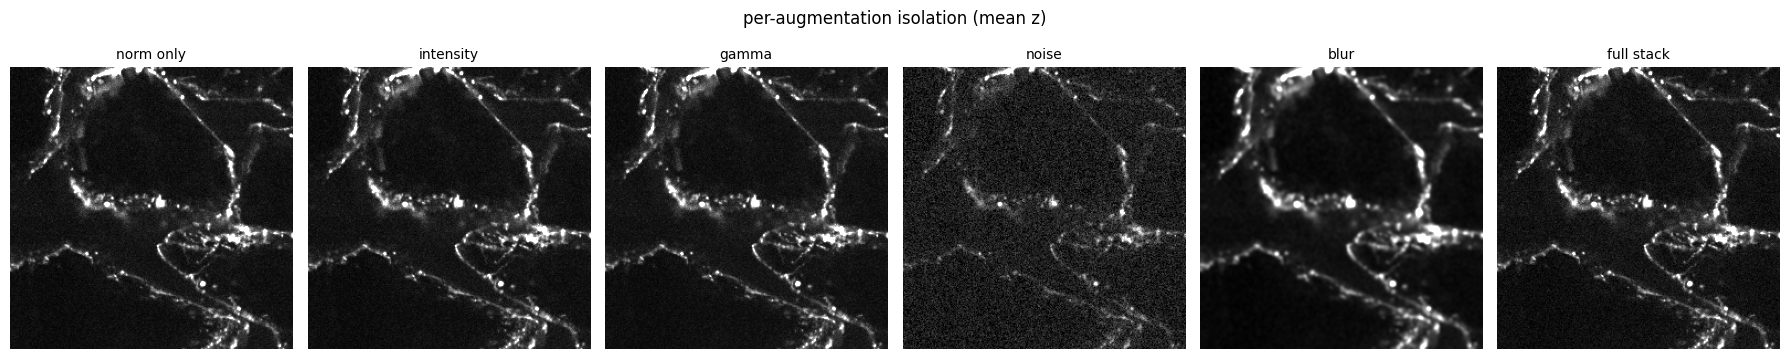

In [8]:
def isolate(name):
    c = copy.deepcopy(cfg)
    for attr in ('aug_intensity', 'aug_gamma', 'aug_noise', 'aug_blur'):
        getattr(c, attr).enabled = (attr == name)
        if attr == name:
            getattr(c, attr).p = 1.0
    c.aug_percrop_norm.enabled = True
    return build_augmentations(c)

def norm_only():
    c = copy.deepcopy(cfg)
    for attr in ('aug_intensity', 'aug_gamma', 'aug_noise', 'aug_blur'):
        getattr(c, attr).enabled = False
    return build_augmentations(c)

modes = [
    ('norm only',  norm_only()),
    ('intensity',  isolate('aug_intensity')),
    ('gamma',      isolate('aug_gamma')),
    ('noise',      isolate('aug_noise')),
    ('blur',       isolate('aug_blur')),
    ('full stack', build_augmentations(cfg)),
]
imgs = [(name, mean_projection(aug(base.clone())[0].numpy())) for name, aug in modes]
lims = percentile_limits(np.concatenate([img.ravel() for _, img in imgs]), 1.0, 99.0)

fig, axes = plt.subplots(1, len(modes), figsize=(3 * len(modes), 3.5))
for ax, (name, img) in zip(axes, imgs):
    show_gray(ax, img, name, lims)
plt.suptitle('per-augmentation isolation (mean z)', y=1.02)
plt.tight_layout(); plt.show()


## 8. A full batch as the DataLoader hands it to the model

This pulls the first batch the DataLoader would emit. Per sample we show one row of 2 globals (`g0 at t1`, `g1 at t2`) and one row of locals (titled with parent, time and z start). The `weak_label` tensor (printed above the figure) is the `(dataset_idx, frame_gap)` long tensor the loss will consume.

globals batch shape  : (4, 2, 1, 10, 256, 256)
locals  batch shape  : (4, 6, 1, 5, 96, 96)
weak_label shape     : (4, 2)
weak_label[:, 0] (dataset_idx): [1, 1, 1, 1]
weak_label[:, 1] (frame_gap)  : [10, 10, 10, 10]


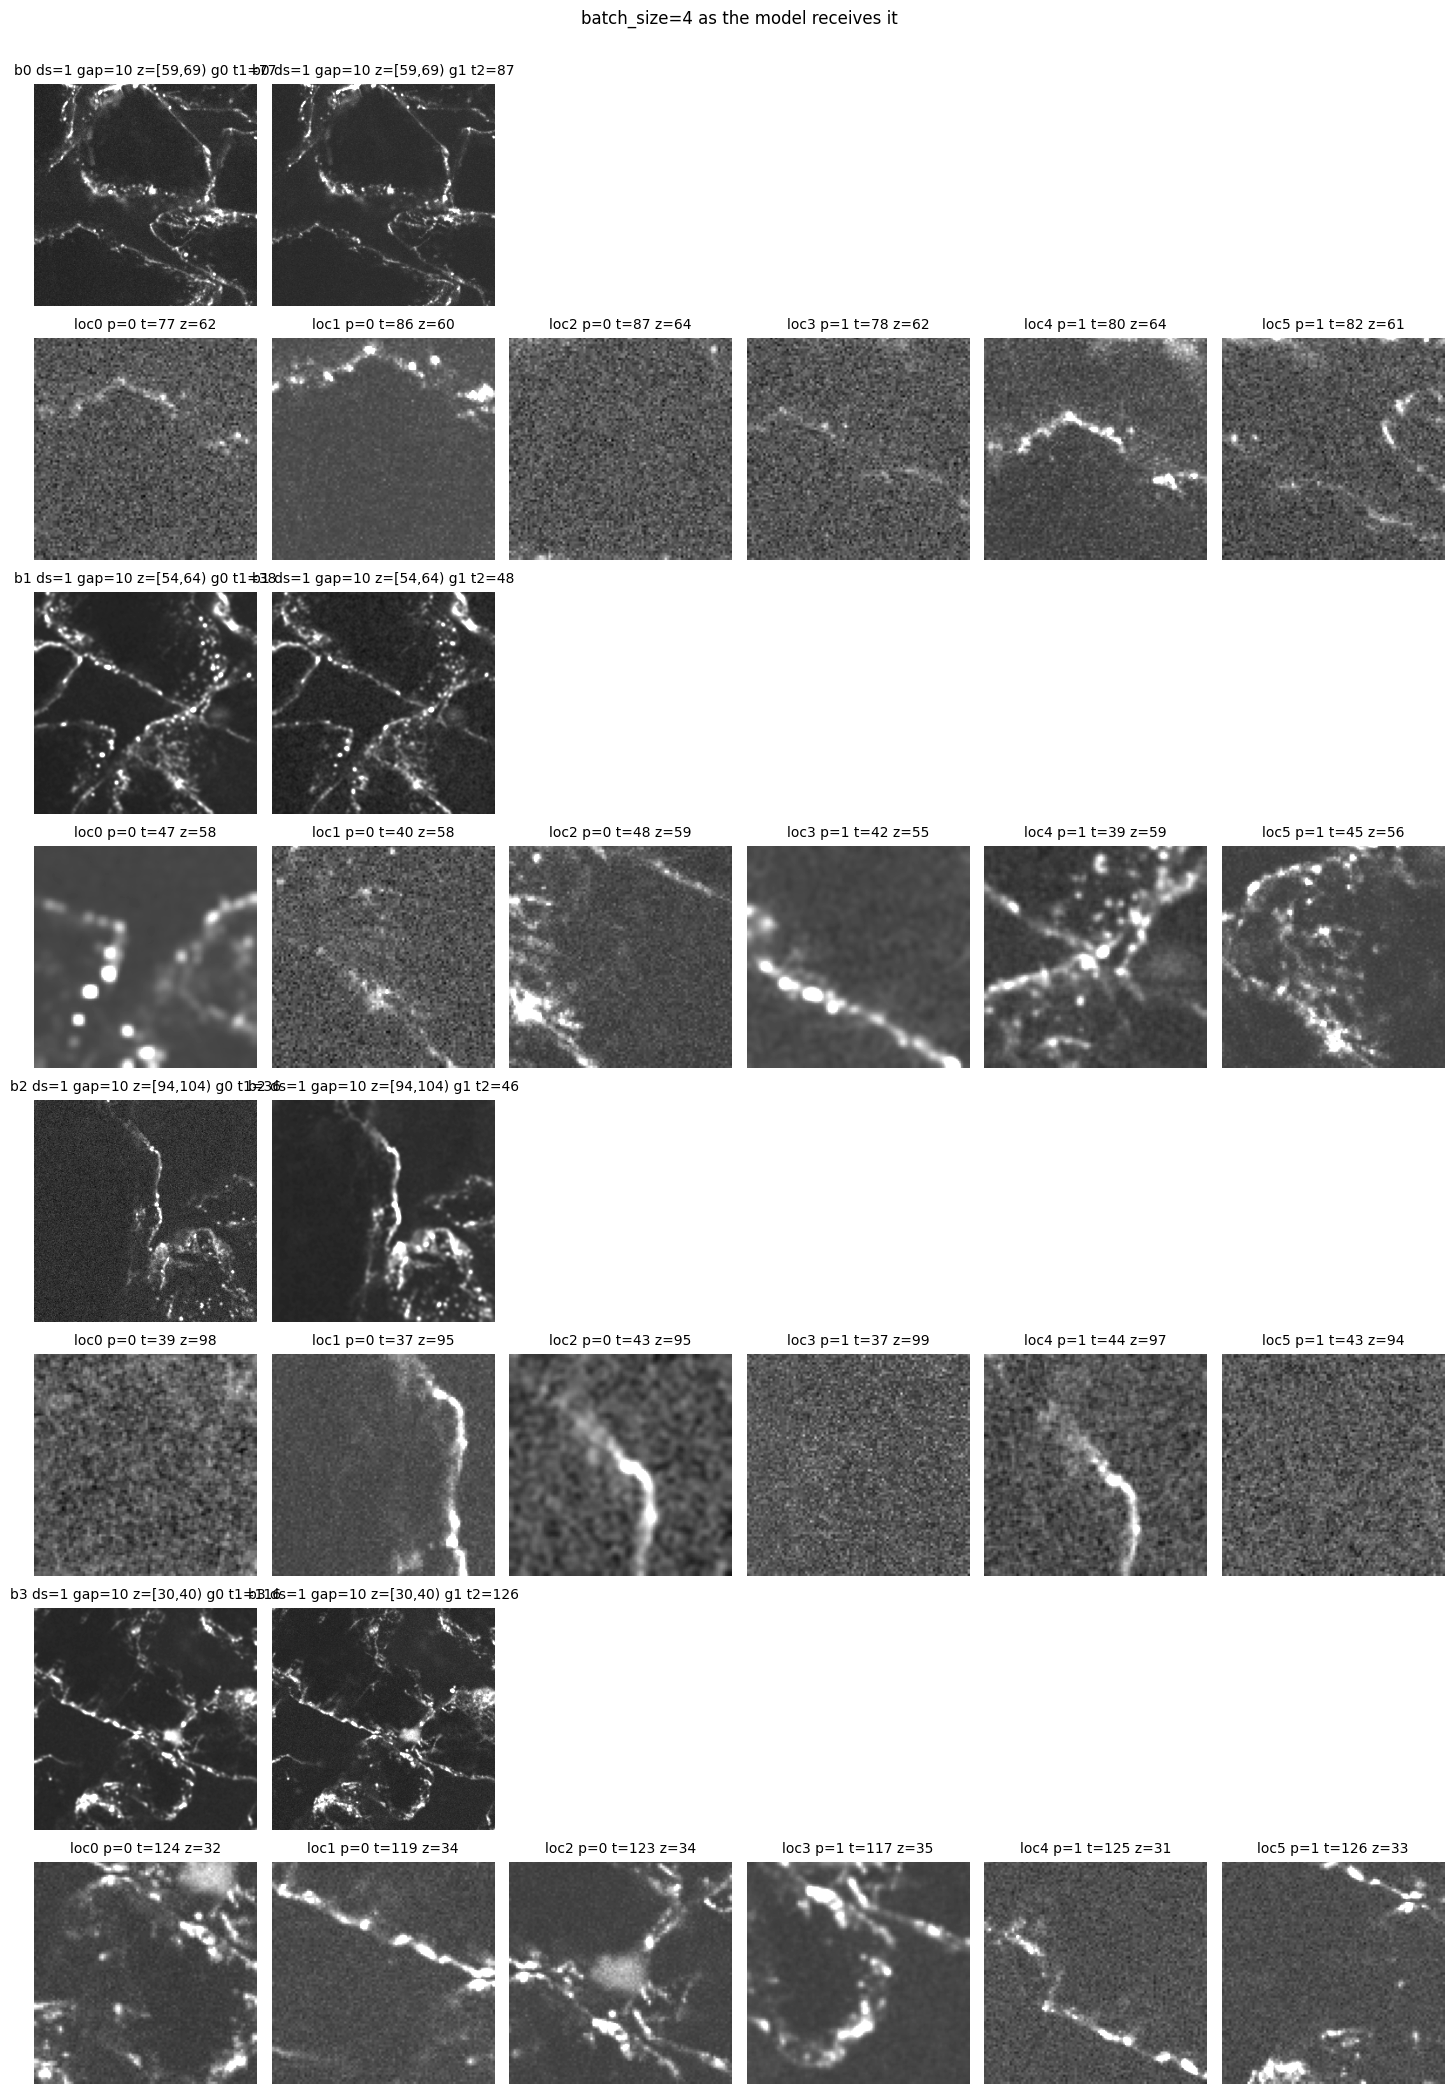

In [9]:
from torch.utils.data import DataLoader

batch_size = 4
loader = DataLoader(
    ds,
    batch_size=batch_size,
    num_workers=0,  # in-process so the notebook stays simple
    worker_init_fn=worker_init_fn,
)

batch = next(iter(loader))
g_b = batch['globals'].numpy()  # (B, 2, 1, z, h, w)
loc_b = batch['locals'].numpy() if 'locals' in batch else None  # (B, n_local, 1, lz, h, w)
weak_b = batch['weak_label']
metas = batch['meta']

print('globals batch shape  :', g_b.shape)
if loc_b is not None:
    print('locals  batch shape  :', loc_b.shape)
print('weak_label shape     :', tuple(weak_b.shape))
print('weak_label[:, 0] (dataset_idx):', weak_b[:, 0].tolist())
print('weak_label[:, 1] (frame_gap)  :', weak_b[:, 1].tolist())

# shared display limits across globals; separate for locals (different z thickness).
glims = percentile_limits(g_b.ravel(), 1.0, 99.0)
llims = percentile_limits(loc_b, 1.0, 99.0) if loc_b is not None else None

n_l_b = loc_b.shape[1] if loc_b is not None else 0
ncols = max(2, n_l_b, 1)
rows_per_sample = 2 if loc_b is not None else 1
total_rows = batch_size * rows_per_sample

fig, axes = plt.subplots(total_rows, ncols, figsize=(2.4 * ncols, 2.6 * total_rows), squeeze=False)
for b in range(batch_size):
    t1 = int(metas['t1'][b]); t2 = int(metas['t2'][b])
    ds_idx = int(metas['dataset_idx'][b])
    fg = int(metas['frame_gap'][b])
    z0 = int(metas['z'][b]); z1 = int(metas['z_end'][b])
    tag = f'b{b} ds={ds_idx} gap={fg} z=[{z0},{z1})'

    row_g = b * rows_per_sample
    # globals: 2 panels (t1, t2); the rest of the row stays blank.
    show_gray(axes[row_g, 0], mean_projection(g_b[b, 0, 0]), f'{tag} g0 t1={t1}', glims)
    show_gray(axes[row_g, 1], mean_projection(g_b[b, 1, 0]), f'{tag} g1 t2={t2}', glims)
    for i in range(2, ncols):
        axes[row_g, i].axis('off')

    if loc_b is not None:
        row_l = row_g + 1
        parents = metas['local_parent'][b].tolist()
        times = metas['local_t'][b].tolist()
        zs = metas['local_z'][b].tolist()
        for i in range(ncols):
            if i < n_l_b:
                show_gray(axes[row_l, i], mean_projection(loc_b[b, i, 0]),
                          f'loc{i} p={parents[i]} t={times[i]} z={zs[i]}', llims)
            else:
                axes[row_l, i].axis('off')

plt.suptitle(f'batch_size={batch_size} as the model receives it', y=1.005)
plt.tight_layout(); plt.show()